# Section 0: Data Preprocessing

Convert 30 MJCF humanoid + bi-arm robot models into the unified screw-theory dataset used
by LEGO. This notebook reproduces the data pipeline that generates
`data/mjcf_test/{screw,dh}/{data,njnt,label,indices}.npy`.

**Source**: `notebook/ae_test/data_creation.ipynb` cells 5-20
**Paper**: arXiv:2604.08636v1 §IV-B (Screw Representation) and §IV-C (Humanoid Model Data Curation)

## What you get
- `KinematicsDatasetBuilder` walk-through
- Screw dataset `(30, 30, 6)`: axis(3) + position(3) per joint slot, 30 slots/robot
- DH dataset `(30, 32, 5)`: θ, d, a, α, τ per joint slot (32 slots = 30 anatomical + 2 TCP)
- Per-robot visualization with joint group color-coding

## Safety
- `save=False` is passed to `create_data_to_classify()` by default → no writes
- The function's `save=True` path is **hardcoded to overwrite `data/mjcf_test/`**: we never use it
- If `SAVE_OUTPUTS=True`, we save the dataset arrays to `./outputs/` manually


In [1]:
# ---- Tutorial flags ----
SAVE_OUTPUTS = False     # if True, save (data, njnt, label, indices) to ./outputs/section0/
VIS_RAW      = False     # if True, visualize all 30 robots (slow, requires display)
VIS_CURATED  = False     # if True, visualize 7 curated robots (faster)
VIS_PREPROC  = False     # if True, visualize post-preprocessing data (~30s per robot)

# ---- Path setup ----
import os, sys
HERE = os.path.abspath('.')
REPO = os.path.abspath('../../')
for p in ['package','package/yoon','package/mujoco_helper','package/kinematics_helper',
          'package/utility','package/bvh_helper','package/smpl','package/motion_retarget',
          'package/irvae_tools','package/kinematics','asset']:
    sys.path.insert(0, os.path.join(REPO, p))
sys.path.insert(0, HERE)

CANONICAL    = os.path.join(HERE, 'canonical/')
TUTORIAL_OUT = os.path.join(HERE, 'outputs/')
if SAVE_OUTPUTS:
    os.makedirs(TUTORIAL_OUT, exist_ok=True)

# RobotCharacteristics uses ../../asset/_robot_info/A-pose.json
os.chdir(os.path.join(REPO, 'notebook/ae_test'))

import numpy as np
import matplotlib.pyplot as plt

from clustering_robots import RobotCharacteristics

print(f'SAVE_OUTPUTS = {SAVE_OUTPUTS}')
print(f'VIS_RAW = {VIS_RAW}, VIS_CURATED = {VIS_CURATED}, VIS_PREPROC = {VIS_PREPROC}')

SAVE_OUTPUTS = False
VIS_RAW = False, VIS_CURATED = False, VIS_PREPROC = False


## 1. The 30-robot dataset

30 diverse humanoid + bi-arm upper-body robots, ranging from small social robots (Pepper, OP3,
iCub) to large research humanoids (Talos, Valkyrie, JAXON) and dual-arm manipulators (Baxter, PR2,
RBY1). All standardized to MuJoCo MJCF format and posed in A-pose.

In [2]:
rc = RobotCharacteristics()
print(f'Number of robots: {len(rc.robot_list)}')
print()
print('Robot list:')
for i, name in enumerate(rc.robot_list):
    print(f'  [{i:2d}] {name}')

RobotCharacteristics for 30initialized
Number of robots: 30

Robot list:
  [ 0] talos
  [ 1] g1
  [ 2] tiago_dual
  [ 3] op3
  [ 4] h1
  [ 5] baxter
  [ 6] digit
  [ 7] ergocub
  [ 8] alex
  [ 9] pr2
  [10] romeo
  [11] icub
  [12] jaxon
  [13] jvrc
  [14] poppy
  [15] valkyrie
  [16] nextage
  [17] sciurus
  [18] igus_op
  [19] armar4
  [20] armar6
  [21] pepper
  [22] hrp4
  [23] bruce
  [24] themis
  [25] apollo
  [26] booster
  [27] x1
  [28] robonaut2
  [29] rby1


In [ ]:
# ---- Check that all 30 robot MJCFs are available ----
# Six models (alex, jaxon, pepper, poppy, romeo, x1) are not redistributed in this repository
# (see README.md, "Models not included in this repository"). The pre-computed dataset in
# data/mjcf_test/ already contains all 30 robots, so only this notebook needs them.
from _robot_info import get_robot_info
missing = []
for name in rc.robot_list:
    info = get_robot_info(name)
    if not os.path.exists(info['mjcf_path']):
        missing.append(name)
if missing:
    raise RuntimeError(
        f'{len(missing)} robot model(s) not found: {missing}.\n'
        'Download them as described in README.md ("Models not included in this repository"), '
        'or skip this notebook - tutorials 01-04 use the pre-computed data in data/mjcf_test/.')
print('All 30 robot models found.')

## 2. Kinematic tree visualization (pre-curated)

Each robot's joint hierarchy was rendered into PNG (see `asset/tree/`). Display one example:

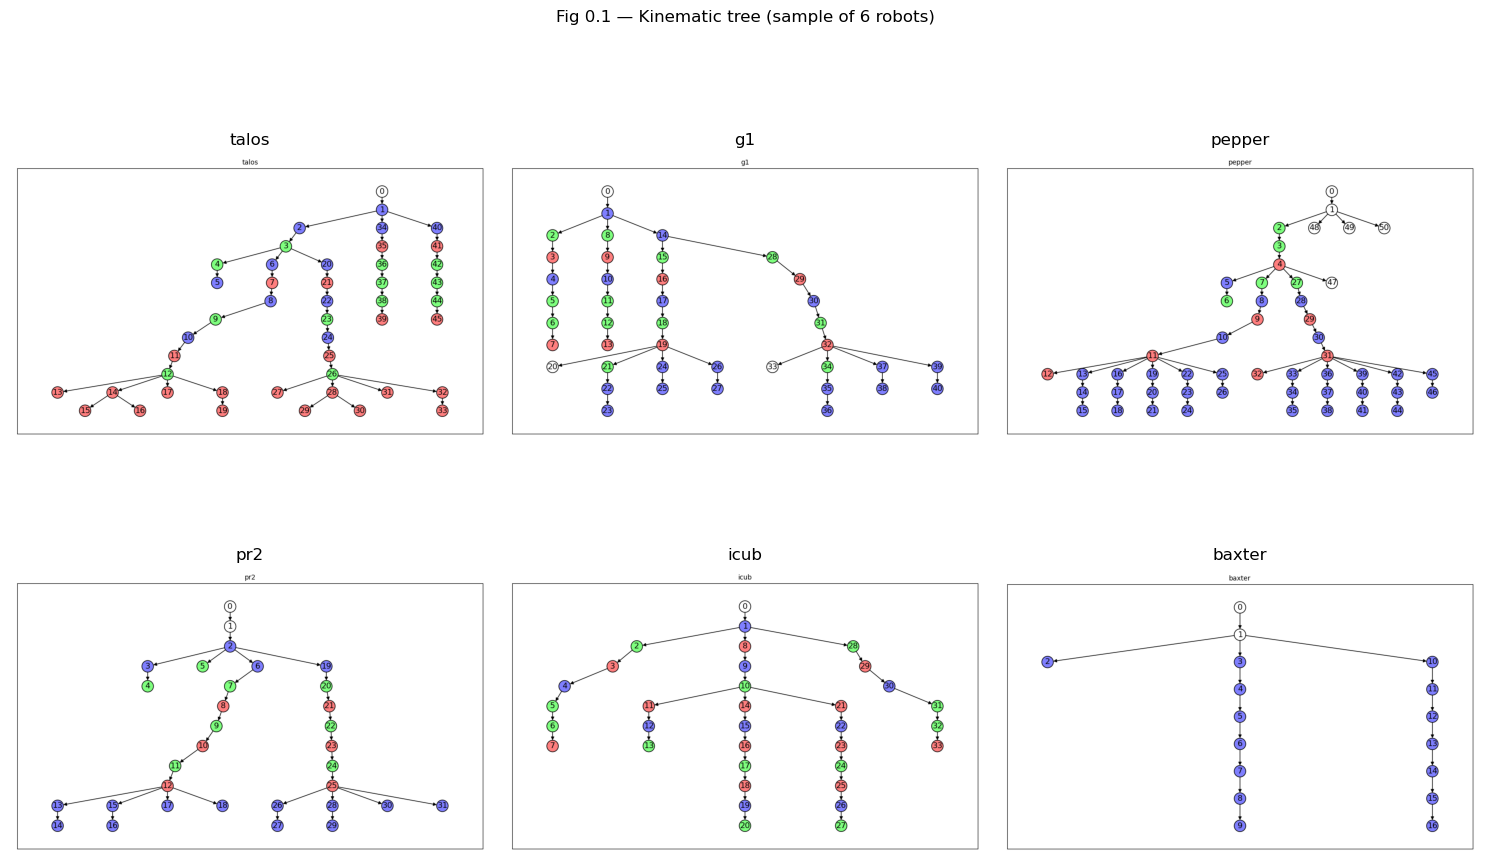

In [3]:
import matplotlib.image as mpimg

tree_dir = os.path.join(REPO, 'asset', 'tree')
example_robots = ['talos', 'g1', 'nextage', 'pr2', 'icub', 'baxter']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, robot in zip(axes.flat, example_robots):
    img_path = os.path.join(tree_dir, f'{robot}_tree.png')
    if os.path.exists(img_path):
        img = mpimg.imread(img_path)
        ax.imshow(img)
        ax.set_title(robot, fontsize=12)
    ax.axis('off')
plt.suptitle('Fig 0.1: Kinematic tree (sample of 6 robots)')
plt.tight_layout()
plt.show()

## 3. Joint groups overlay

Visualize joints colored by anatomical group (torso/neck/shoulder/.../wrist).
Each group gets a distinct color, helping see how the screw representation captures
the 14 anatomical categories.

Setting `VIS_CURATED = True` opens 7 robots one by one (interactive, needs display).

In [4]:
if VIS_CURATED:
    rc.curate = True
    rc._initialize_robots()
    curated = ['tiago_dual', 'op3', 'icub', 'jaxon', 'poppy', 'armar4', 'robonaut2']
    for name in curated:
        rc._initialize_env(name)
        rc.visualize_robot_joints_with_arrows(name)
else:
    print('VIS_CURATED=False: skipping. Set True to view 7 curated robots interactively.')

VIS_CURATED=False: skipping. Set True to view 7 curated robots interactively.


## 4. Build the screw and DH datasets

`KinematicsDatasetBuilder` walks the curated MJCF model for each robot in A-pose, extracts
joint axes and positions, applies the missing-data fill rules (axis ε-threshold, position
local-average, shoulder-to-base normalization), and produces aligned `(30, max_slots, feat_dim)`
arrays.

| repr_kind | shape | feat_dim | extra |
|---|---|---|---|
| `'screw'` | (30, 30, 6) | axis(3) + position(3) | 14 anatomical groups, max 30 joints/robot |
| `'dh'` | (30, 32, 5) | θ, d, a, α, τ | + 2 TCP groups (right_tcp, left_tcp) |

Call `create_data_to_classify(save=False)`: the `save=True` path would overwrite
the project canonical files. **We never use it.**

In [5]:
rc.curate = True
rc._initialize_robots()

print('Building screw dataset...')
ds_screw = rc.create_data_to_classify(save=False, repr_kind='screw')
print(f'  screw: {ds_screw.arrays.shape}  (30 robots × 30 slots × 6 features)')
print(f'  max_joints_per_group = {ds_screw.max_joints_per_group}')
print(f'  selected_indices shape = {ds_screw.selected_indices.shape}')
print()

print('Building DH dataset...')
ds_dh = rc.create_data_to_classify(save=False, repr_kind='dh')
print(f'  dh:    {ds_dh.arrays.shape}')
print(f'  max_joints_per_group = {ds_dh.max_joints_per_group}')

RobotCharacteristics for 30initialized
Building screw dataset...


  screw: (30, 30, 6)  (30 robots × 30 slots × 6 features)
  max_joints_per_group = [6, 4, 1, 3, 1, 1, 1, 3, 1, 3, 1, 1, 1, 3]
  selected_indices shape = (4, 14)

Building DH dataset...


  dh:    (30, 32, 5)
  max_joints_per_group = [6, 4, 1, 3, 1, 1, 1, 3, 1, 1, 3, 1, 1, 1, 3, 1]


## 5. Inspect the screw tensor

Heatmap of `(30 robots, 180 features)` flattened. Sparsity visualizes which slots have
valid joints (high axis-norm), virtual joints / position anchors (axis = 0 but pos ≠ 0),
and truly empty slots (entire row = 0).

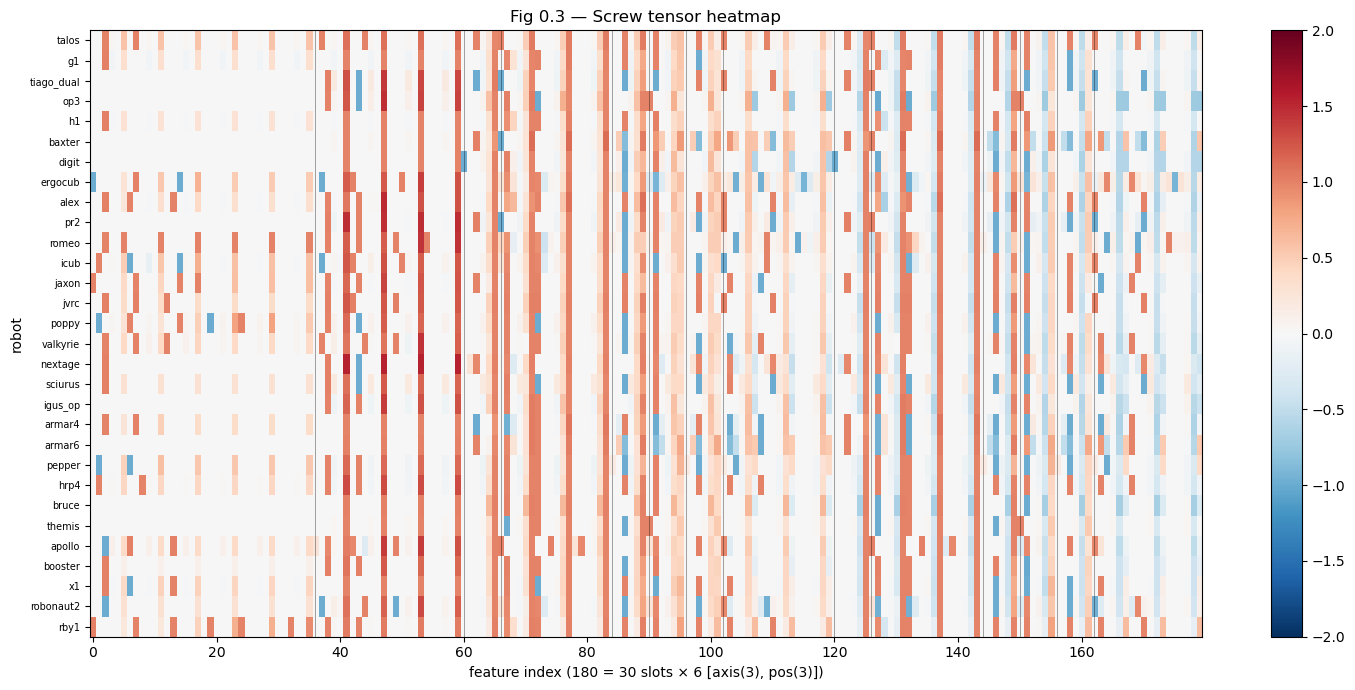

In [6]:
flat = ds_screw.arrays.reshape(30, -1)
labels = np.array(ds_screw.labels)

fig, ax = plt.subplots(figsize=(15, 7))
im = ax.imshow(flat, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
ax.set_yticks(range(30)); ax.set_yticklabels(labels, fontsize=7)
ax.set_xlabel('feature index (180 = 30 slots × 6 [axis(3), pos(3)])')
ax.set_ylabel('robot')
ax.set_title('Fig 0.3: Screw tensor heatmap')

# Mark group boundaries
group_sizes = ds_screw.max_joints_per_group
boundaries = np.cumsum(group_sizes) * 6
for b in boundaries[:-1]:
    ax.axvline(b, color='k', linewidth=0.5, alpha=0.5)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 6. Axis-norm histogram per group

For each anatomical group, plot the distribution of axis-norms across all 30 robots' slots.
This shows the ε=0.5 active-joint threshold visually.

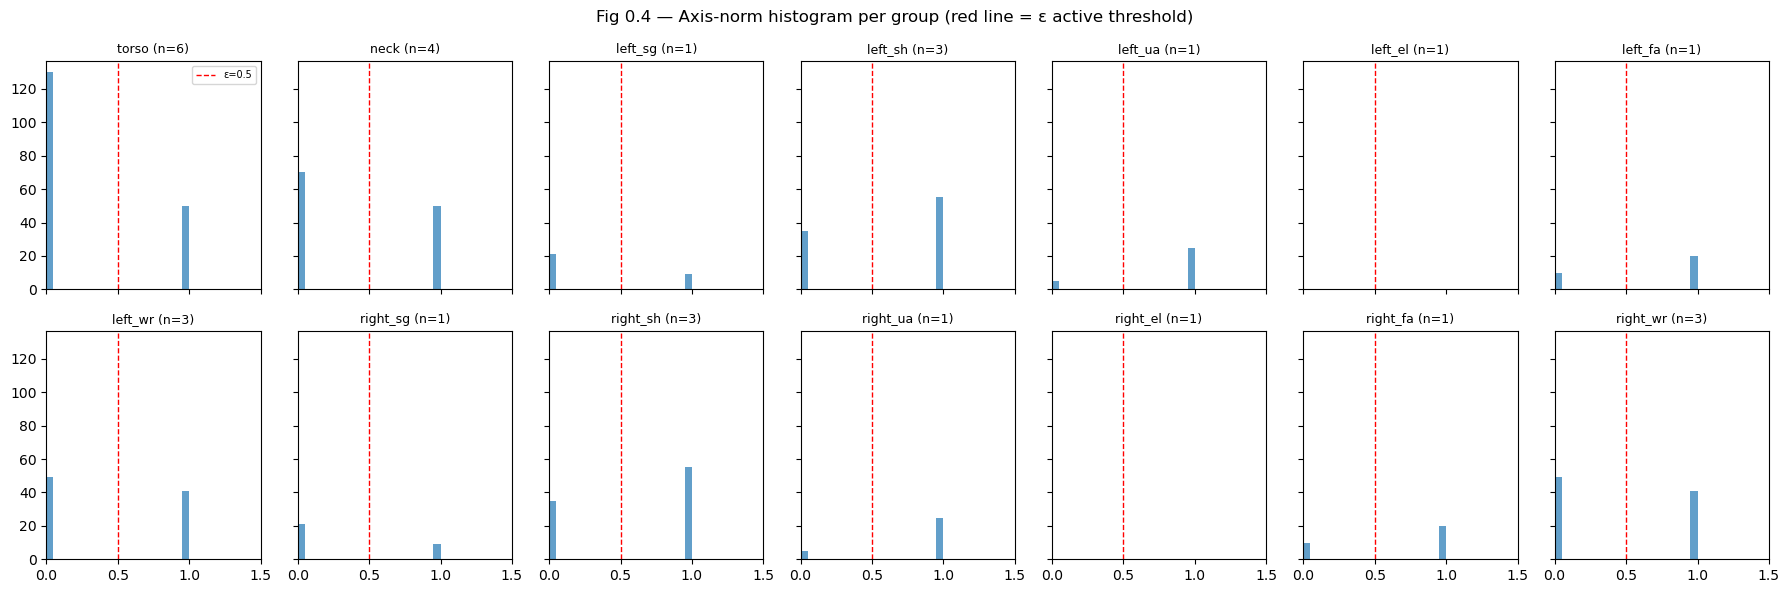

In [7]:
group_names = ['torso','neck',
               'left_sg','left_sh','left_ua','left_el','left_fa','left_wr',
               'right_sg','right_sh','right_ua','right_el','right_fa','right_wr']

# Compute axis norms: data shape (30, 30, 6) → for each slot, |axis|
axis_all = ds_screw.arrays[:, :, :3]                          # (30, 30, 3)
axis_norm = np.linalg.norm(axis_all, axis=2)                  # (30 robots, 30 slots)

# Group slot indices via group_sizes
group_starts = np.concatenate([[0], np.cumsum(group_sizes)])

fig, axes = plt.subplots(2, 7, figsize=(18, 6), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    s, e = group_starts[i], group_starts[i+1]
    vals = axis_norm[:, s:e].ravel()
    ax.hist(vals, bins=20, color='C0', alpha=0.7)
    ax.axvline(0.5, color='red', linestyle='--', linewidth=1, label='ε=0.5')
    ax.set_title(f'{group_names[i]} (n={e-s})', fontsize=9)
    ax.set_xlim(0, 1.5)
    if i == 0: ax.legend(fontsize=7)

plt.suptitle('Fig 0.4: Axis-norm histogram per group (red line = ε active threshold)')
plt.tight_layout()
plt.show()

## 7. (Optional) Visualize preprocessed data

Render each robot from its preprocessed (axis, pos) tensor: verifies the curation/normalization
preserved the structure.

`VIS_PREPROC = True` renders to mp4 (needs Xvfb and ~30s per robot).

In [8]:
if VIS_PREPROC:
    data_to_vis = {robot_name: info['data_to_classify_dh']
                   for robot_name, info in rc.classifying_joint_info.items()
                   if 'data_to_classify_dh' in info}
    clip = rc.visualize_data_to_classify(data_to_vis, save_video=True, vis=True, xml=True, repr_kind='dh')
    print('Rendered video → mp4 in current dir')
else:
    print('VIS_PREPROC=False: skipping. Set True to render mp4.')

VIS_PREPROC=False: skipping. Set True to render mp4.


## 8. (Optional) Save datasets to tutorial outputs

`SAVE_OUTPUTS=True` writes to `outputs/section0/` (NOT to project canonical
`data/mjcf_test/`).

In [9]:
if SAVE_OUTPUTS:
    out_dir = os.path.join(TUTORIAL_OUT, 'section0')
    for repr_kind, ds in [('screw', ds_screw), ('dh', ds_dh)]:
        sub = os.path.join(out_dir, repr_kind)
        os.makedirs(sub, exist_ok=True)
        np.save(os.path.join(sub, 'data.npy'), ds.arrays)
        np.save(os.path.join(sub, 'label.npy'), np.array(ds.labels))
        np.save(os.path.join(sub, 'njnt.npy'), np.array(ds.max_joints_per_group))
        np.save(os.path.join(sub, 'indices.npy'), np.array(ds.selected_indices))
        print(f'Saved {repr_kind} → {sub}')
    print()
    print('NOTE: project canonical data/mjcf_test/{screw,dh}/ NOT touched.')
else:
    print('SAVE_OUTPUTS=False: skipping. Datasets exist in memory as ds_screw, ds_dh.')

SAVE_OUTPUTS=False: skipping. Datasets exist in memory as ds_screw, ds_dh.


## 9. Sanity check vs canonical data

Compare the freshly-built dataset against the canonical `data/mjcf_test/screw/data.npy`
(the dataset the pretrained models were trained on). Small differences (max ~0.01) are
expected: a few robot models in LEGO-assets received minor joint-position fixes after the
dataset was built. The joint counts (`njnt`) match exactly.

In [10]:
canonical_screw = np.load(os.path.join(CANONICAL, 'data', 'screw', 'data.npy'))
canonical_njnt  = np.load(os.path.join(CANONICAL, 'data', 'screw', 'njnt.npy'))

ours_eq_canon = np.allclose(ds_screw.arrays, canonical_screw, atol=1e-6)
njnt_eq = np.array_equal(np.array(ds_screw.max_joints_per_group), canonical_njnt)

print(f'Our screw data matches canonical: {ours_eq_canon}')
print(f'Our njnt matches canonical:        {njnt_eq}')
if not ours_eq_canon:
    diff = np.abs(ds_screw.arrays - canonical_screw)
    print(f'  max diff: {diff.max():.6f}')
    print(f'  mean diff: {diff.mean():.6f}')

Our screw data matches canonical: False
Our njnt matches canonical:        True
  max diff: 0.008584
  mean diff: 0.000024


---

## Summary
- Loaded 30-robot list from `RobotCharacteristics`
- Built (30, 30, 6) screw + (30, 32, 5) DH datasets via `KinematicsDatasetBuilder`
- Verified ε=0.5 active threshold partitions axis norms cleanly
- Compared to canonical: same joint counts, values within ~0.01

**Next**: [`01_latent_space_learning.ipynb`](./01_latent_space_learning.ipynb) trains an AE on these arrays.